In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [2]:
!cp "/content/gdrive/MyDrive/football photo/football analysis.vi1yolo26.zip" /content/

cp: cannot stat '/content/gdrive/MyDrive/football photo/football analysis.vi1yolo26.zip': No such file or directory


In [3]:
import os
import glob

zip_files = list({os.path.abspath(f) for f in glob.glob("/content/*.zip")})

if not zip_files:
    print("❌ No zip files found. Please upload one.")
elif len(zip_files) == 1:
    zip_to_extract = zip_files[0]
    print(f"✅ Auto-selected: {zip_to_extract}")
else:
    print("📦 Multiple zip files found:")
    for i, zf in enumerate(zip_files):
        print(f"{i+1}. {os.path.basename(zf)} ({zf})")
    choice = int(input("Choose number: ")) - 1
    zip_to_extract = zip_files[choice]

✅ Auto-selected: /content/football analysis.v1i.yolo26.zip


In [4]:
if 'zip_to_extract' in locals():
    print(f"📂 Extracting: {os.path.basename(zip_to_extract)}")
    !unzip -o "{zip_to_extract}" -d /content/
    print("✅ Extraction complete!")
    !ls -la /content | head -10

📂 Extracting: football analysis.v1i.yolo26.zip
Archive:  /content/football analysis.v1i.yolo26.zip
 extracting: /content/test/images/frame_000118_jpg.rf.8e76467fa60a791562fddf64a53fc450.jpg  
 extracting: /content/test/images/frame_000136_jpg.rf.cb1d3882005e97c017ef3f310fa82358.jpg  
 extracting: /content/test/images/frame_000085_jpg.rf.6f6e5981145e7291afc42e14412d324f.jpg  
 extracting: /content/test/images/frame_000015_jpg.rf.df8f4f5598090bc6a24ecf083c1b1180.jpg  
 extracting: /content/test/images/frame_000135_jpg.rf.75a61d60a02a3db1f774b9d4964198f7.jpg  
 extracting: /content/test/images/frame_000151_jpg.rf.c075e23b59ce3d5d1e5d75e459ef5afb.jpg  
 extracting: /content/test/images/frame_000175_jpg.rf.291b9a4c4d405c5cf45258f1cdd687f1.jpg  
 extracting: /content/test/images/frame_000043_jpg.rf.4c21744be83b00b2be128e7173cf1660.jpg  
 extracting: /content/test/images/frame_000184_jpg.rf.6bfa3c49b383f32c669aa7161a7eba55.jpg  
 extracting: /content/train/images/frame_000172_jpg.rf.26dec0ed9

In [5]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 7.5 MB/s eta 0:00:00


In [6]:
!yolo detect train data=/content/data.yaml model=yolov8n.pt epochs=50 imgsz=640

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torch

In [7]:
!yolo detect predict model=/content/runs/detect/train/weights/best.pt source=/content/valid/images save=True

Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs

image 1/12 /content/valid/images/frame_000000_jpg.rf.3641f9a5216ec4068aca11c666e54c99.jpg: 640x640 20 players, 3 referees, 8.1ms
image 2/12 /content/valid/images/frame_000016_jpg.rf.9e2018a67623849135c819d0f549c011.jpg: 640x640 18 players, 2 referees, 8.2ms
image 3/12 /content/valid/images/frame_000078_jpg.rf.be37e622893781884fa1afa790e20bc3.jpg: 640x640 20 players, 1 referee, 7.5ms
image 4/12 /content/valid/images/frame_000094_jpg.rf.770d9834e07245aa495f6d81dffbbf81.jpg: 640x640 20 players, 9.9ms
image 5/12 /content/valid/images/frame_000106_jpg.rf.1c5f72c392724b2c57d2ec7113533954.jpg: 640x640 16 players, 7.8ms
image 6/12 /content/valid/images/frame_000108_jpg.rf.a618670e4d1e3cf4572a451618e1d1cb.jpg: 640x640 15 players, 10.1ms
image 7/12 /content/valid/images/frame_000148_jpg.rf.bc1c58e71099f4c6e3cb4c2afd696ba8.jpg: 640x64

In [8]:
!ls /content/runs/detect/train-3/weights/

ls: cannot access '/content/runs/detect/train-3/weights/': No such file or directory


In [9]:
!yolo detect predict model=/content/runs/detect/train-3/weights/best.pt source=/content/valid/images save=True

Traceback (most recent call last):
  File "/usr/local/bin/yolo", line 8, in <module>
    sys.exit(entrypoint())
             ^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/cfg/__init__.py", line 1093, in entrypoint
    model = YOLO(model, task=task)
            ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/models/yolo/model.py", line 82, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/engine/model.py", line 133, in __init__
    self._load(model, task=task)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/engine/model.py", line 249, in _load
    self.model, self.ckpt = load_checkpoint(weights)
                            ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/nn/tasks.py", line 1902, in load_checkpoint
    ckpt, weight = torch_safe_load(weight)  # load ckpt
                   ^^^^^^^^

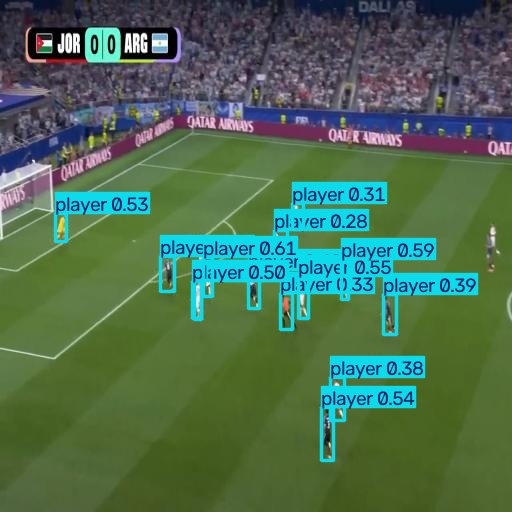

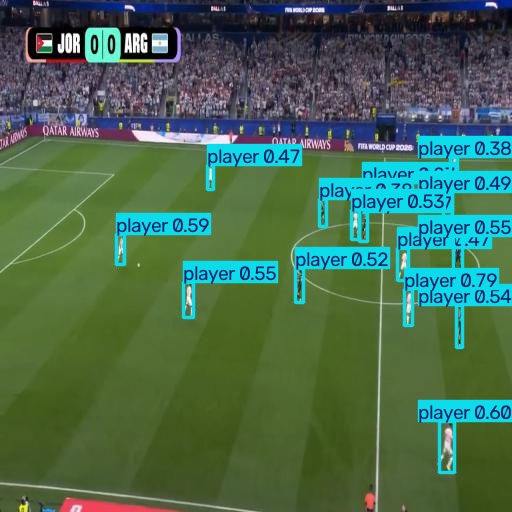

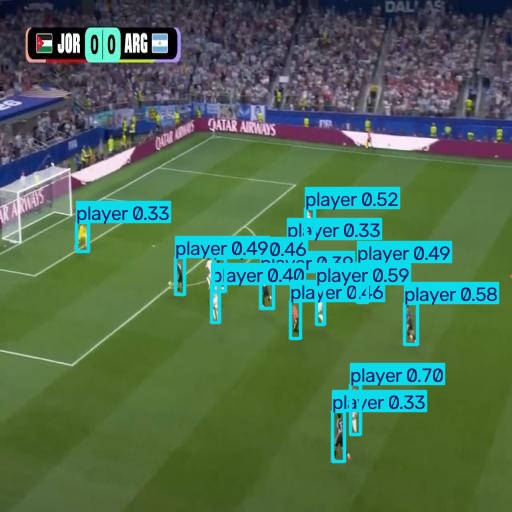

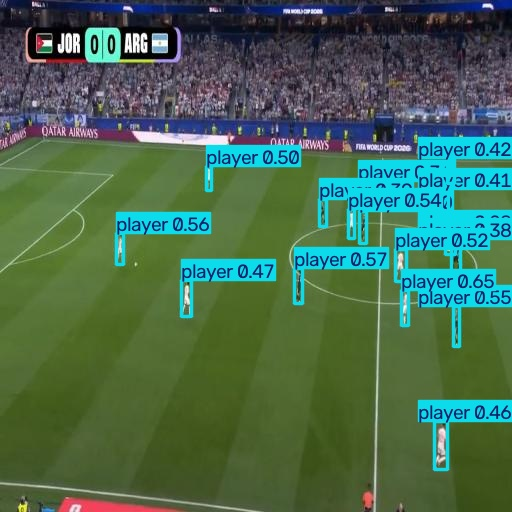

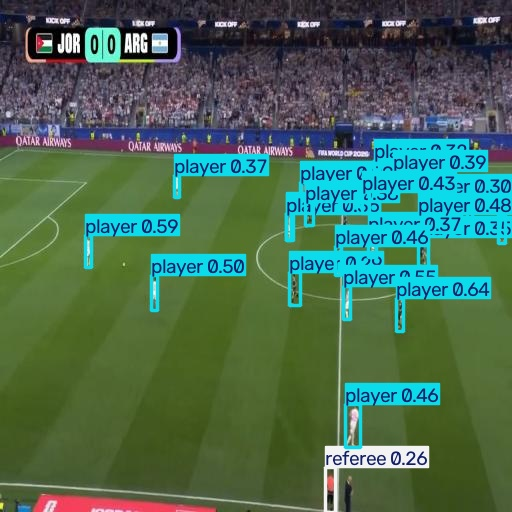

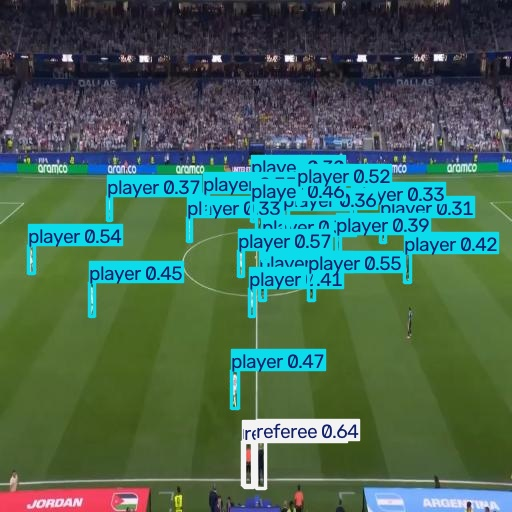

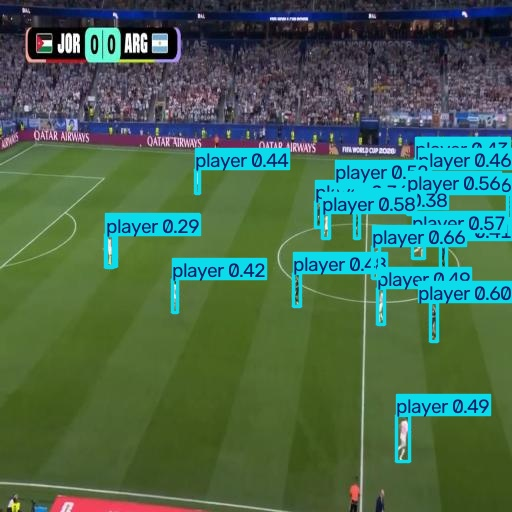

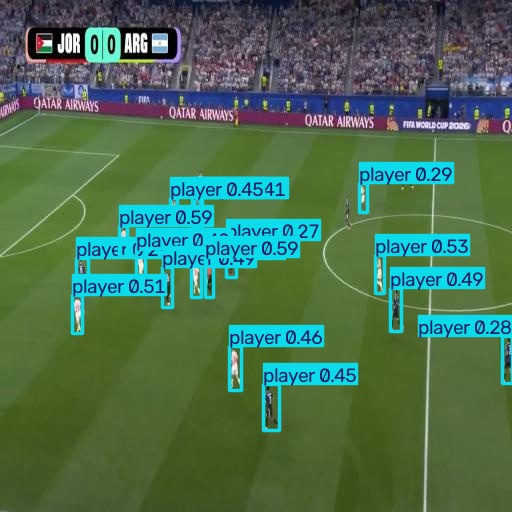

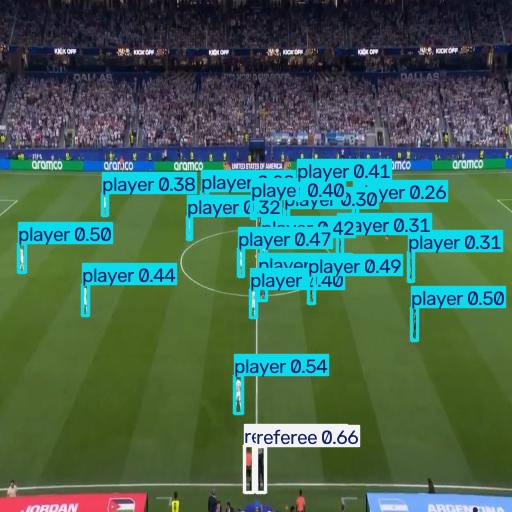

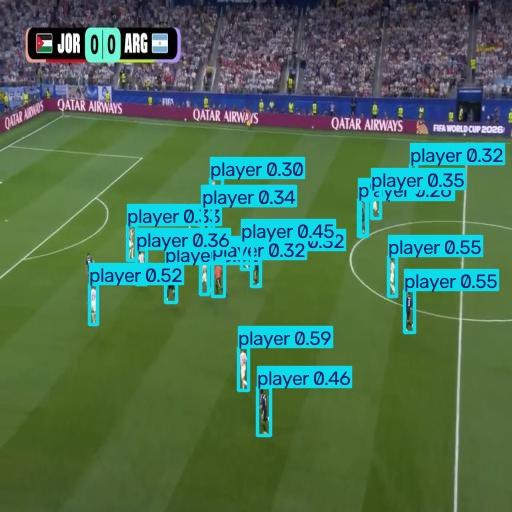

In [10]:
import glob
from IPython.display import Image, display

for image_path in glob.glob('/content/runs/detect/predict/*.jpg')[:10]:
    display(Image(filename=image_path, height=480))
    print('\n')

In [11]:
import pandas as pd

df = pd.read_csv('/content/runs/detect/train/results.csv')

In [12]:
last = df.iloc[-1]

In [13]:
print("Precision:", last['metrics/precision(B)'])
print("Recall:", last['metrics/recall(B)'])
print("mAP@50:", last['metrics/mAP50(B)'])
print("mAP@50:95:", last['metrics/mAP50-95(B)'])

Precision: 0.73727
Recall: 0.72054
mAP@50: 0.76516
mAP@50:95: 0.4578


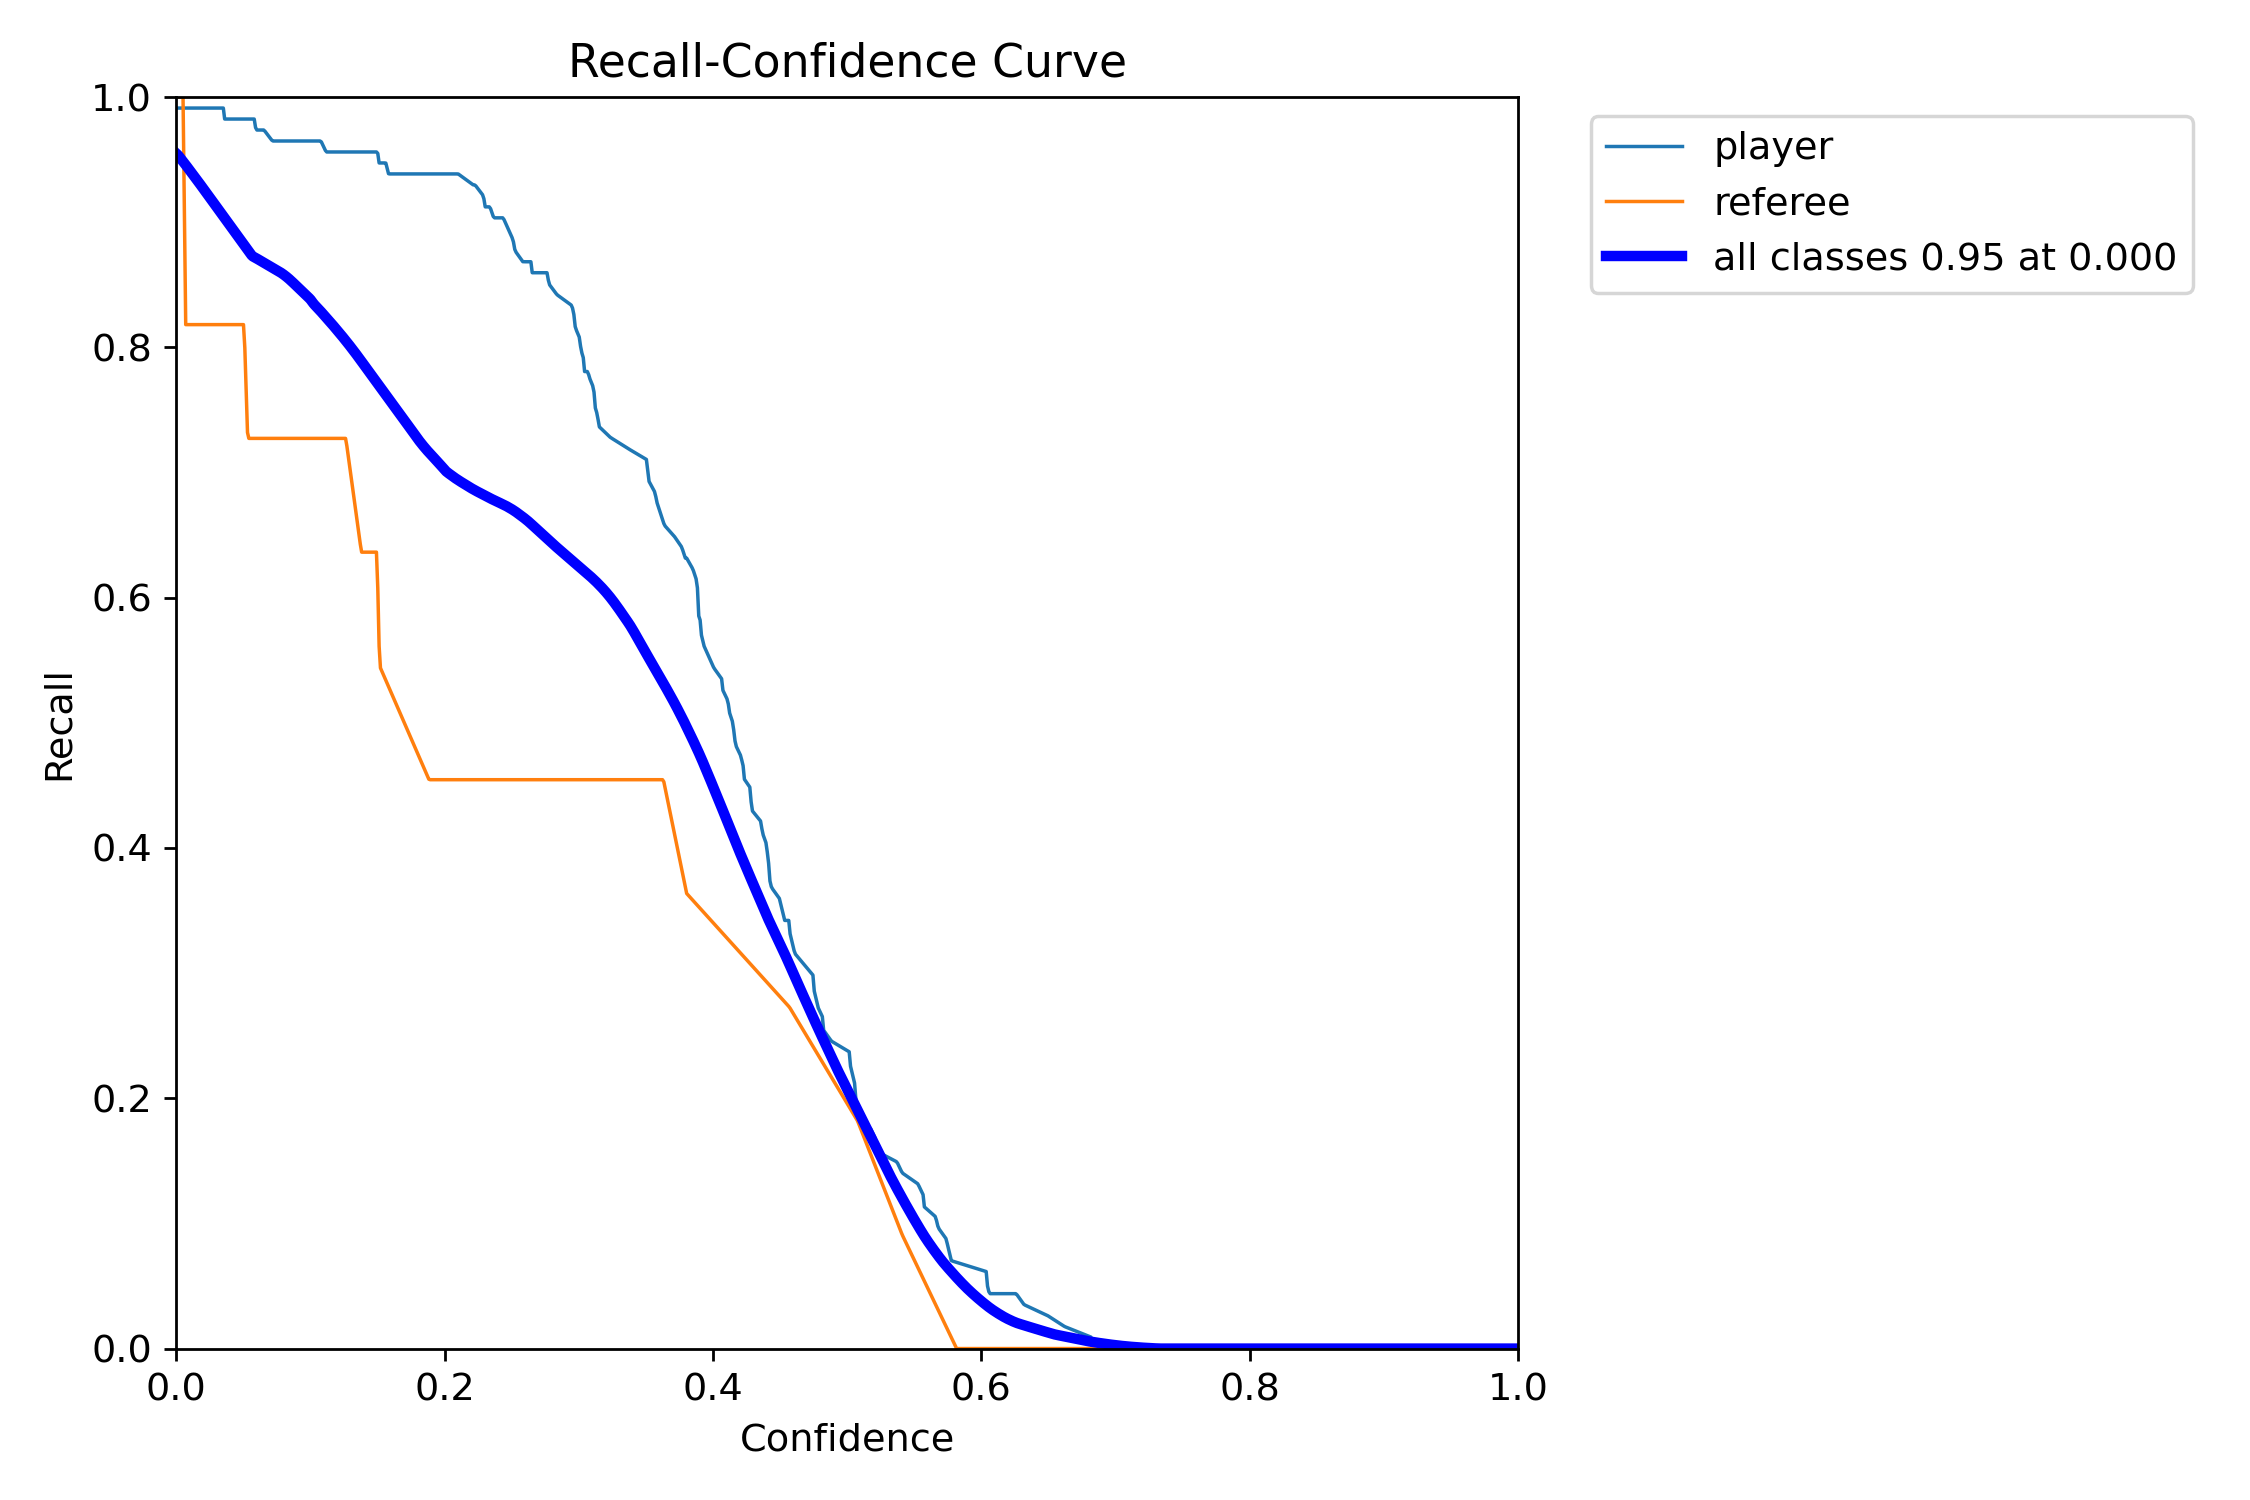

In [14]:
from IPython.display import Image

Image(filename='/content/runs/detect/train/BoxR_curve.png', height=480)

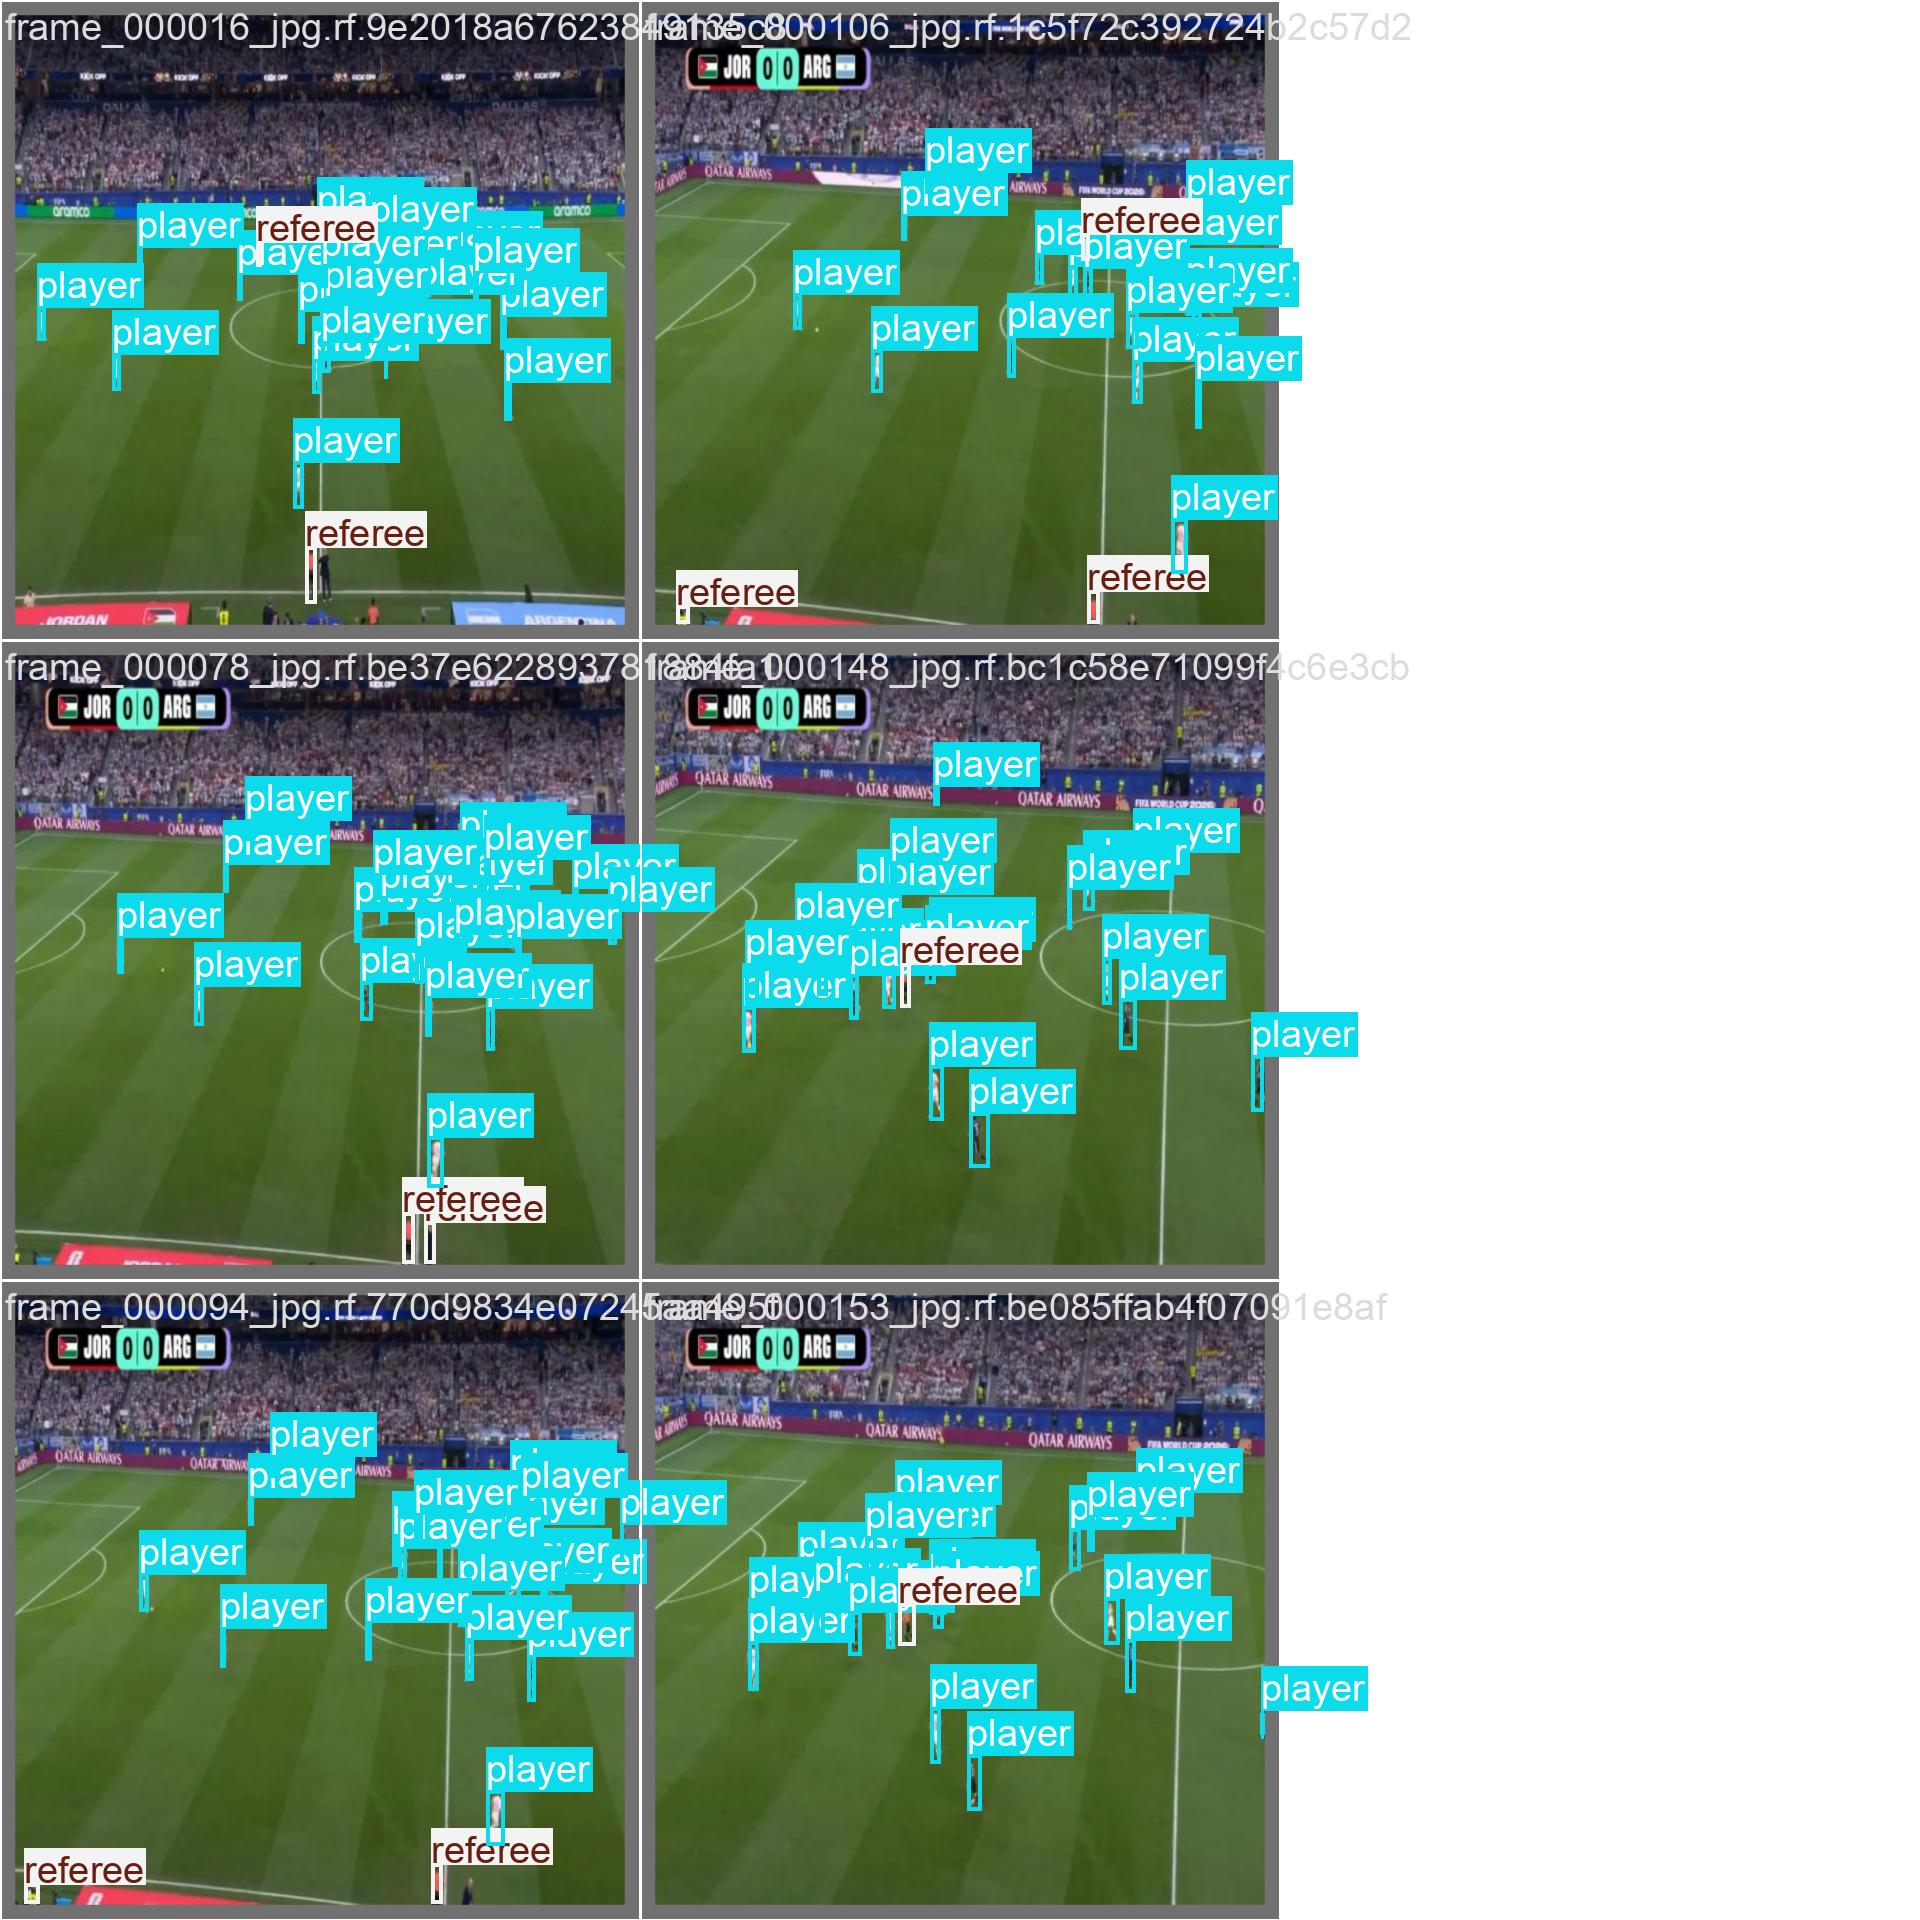

In [15]:
from IPython.display import Image

Image(filename='/content/runs/detect/train/val_batch0_labels.jpg', height=480)

In [16]:
import os

for f in os.listdir('/content/runs/detect/train'):
    if "confusion" in f.lower():
        print(f)

confusion_matrix.png
confusion_matrix_normalized.png


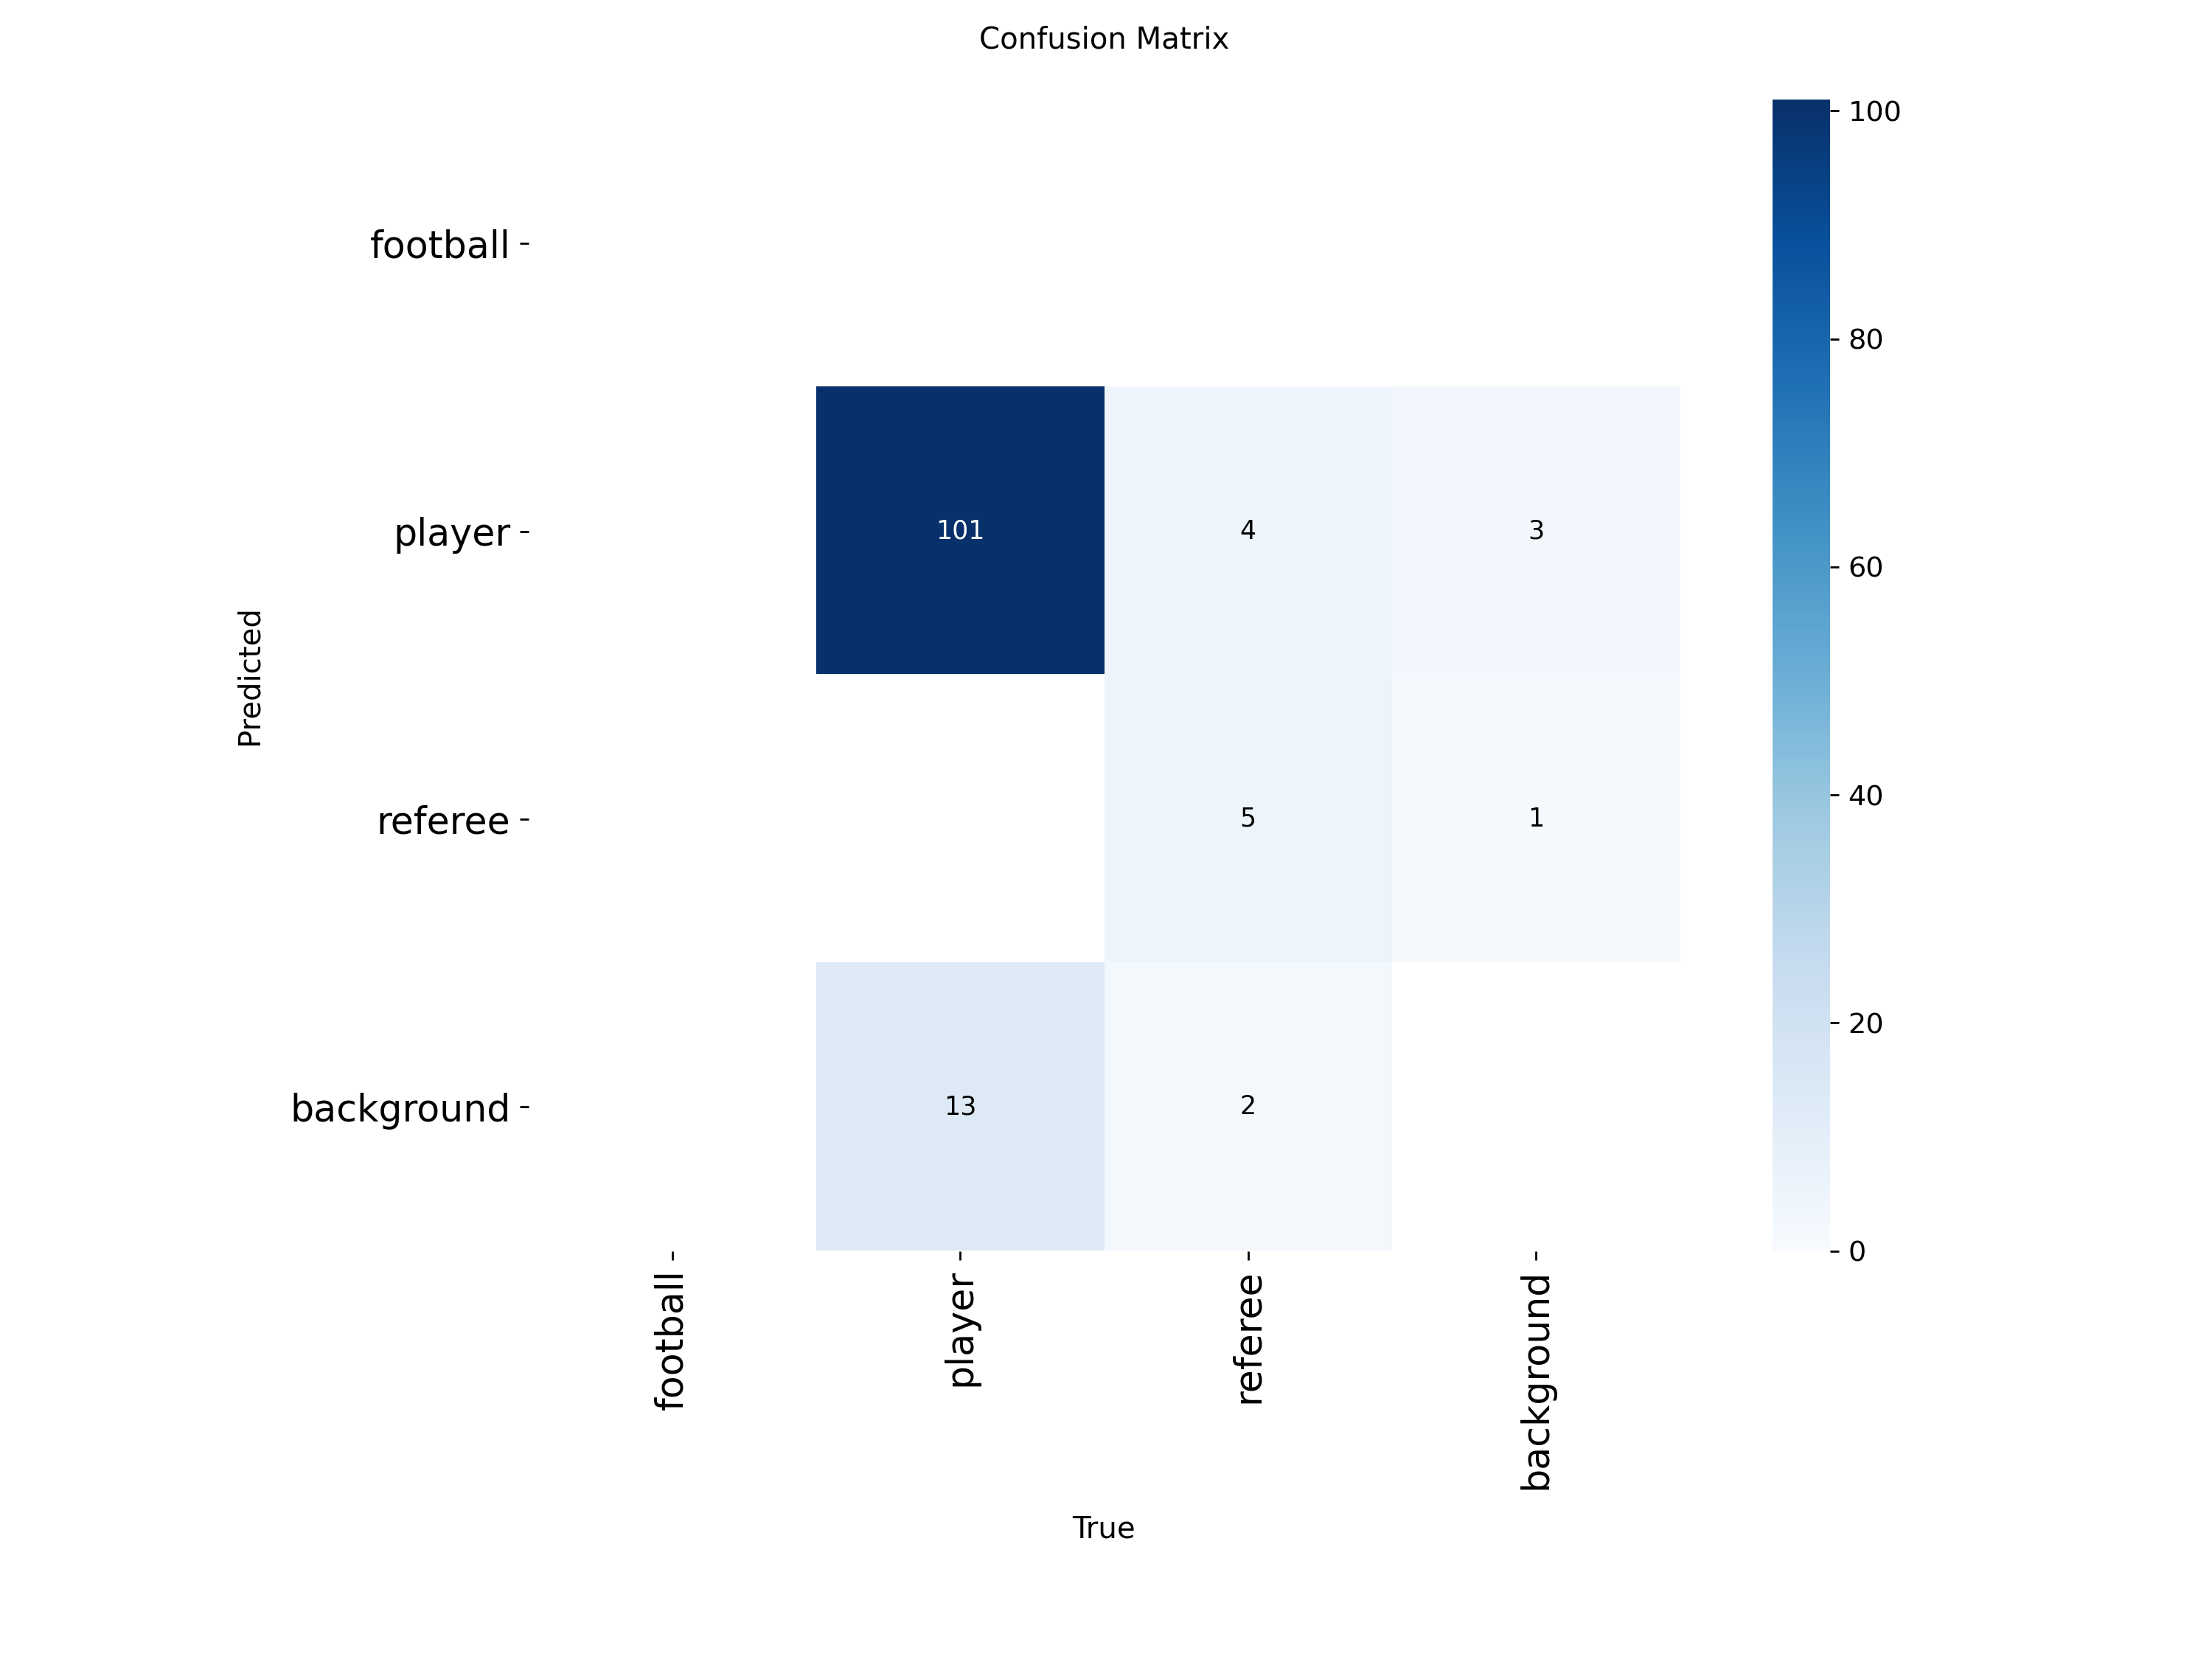

In [17]:
from IPython.display import Image

Image(filename='/content/runs/detect/train/confusion_matrix.png', height=480)

In [22]:
import os

for f in os.listdir('/content'):
    if f.endswith('.MP4'):
        print(f)

IMG_1182.MP4


In [25]:
import cv2

video_path = "/content/IMG_1182.MP4"

cap = cv2.VideoCapture(video_path)

print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

cap.release()

Width: 1280
Height: 720
FPS: 29.97697031729785
Frames: 3905


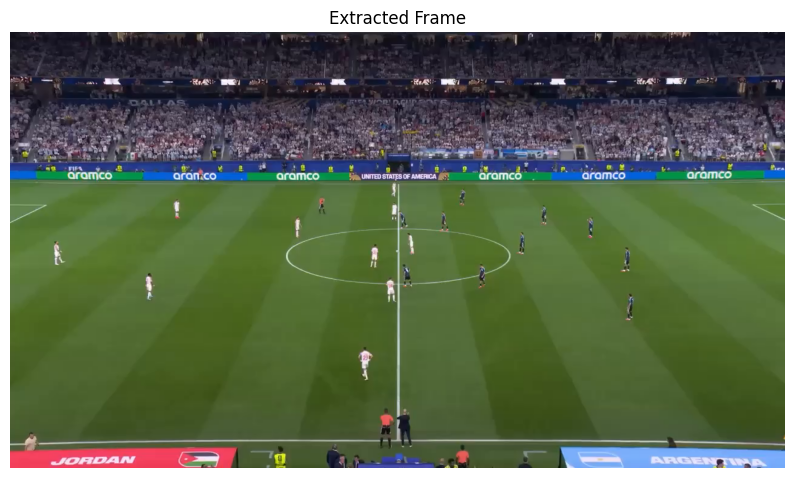

In [26]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture("/content/IMG_1182.MP4")

ret, frame = cap.read()

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,6))
plt.imshow(frame_rgb)
plt.title("Extracted Frame")
plt.axis("off")

cap.release()

In [27]:
import cv2

video_path = "/content/IMG_1182.MP4"

cap = cv2.VideoCapture(video_path)

print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

cap.release()

Width: 1280
Height: 720
FPS: 29.97697031729785
Frames: 3905


In [28]:
import os

for root, dirs, files in os.walk('/content/runs'):
    for file in files:
        if file == 'best.pt':
            print(os.path.join(root, file))

/content/runs/detect/train/weights/best.pt


In [29]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

print("Model Loaded Successfully")

Model Loaded Successfully



0: 384x640 15 players, 2 referees, 6.1ms
Speed: 21.5ms preprocess, 6.1ms inference, 18.0ms postprocess per image at shape (1, 3, 384, 640)


(np.float64(-0.5), np.float64(1279.5), np.float64(719.5), np.float64(-0.5))

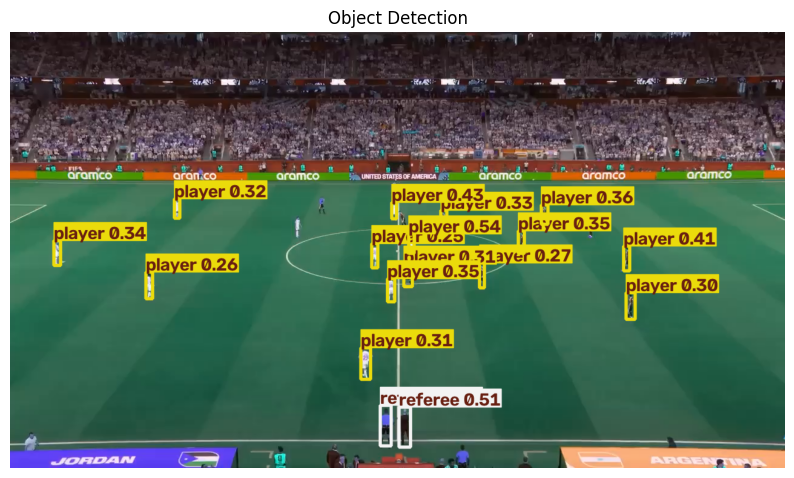

In [30]:
results = model(frame)

annotated = results[0].plot()

plt.figure(figsize=(10,6))
plt.imshow(annotated)
plt.title("Object Detection")
plt.axis("off")

In [31]:
!pip install deep-sort-realtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 117.0 MB/s eta 0:00:00


In [32]:
from deep_sort_realtime.deepsort_tracker import DeepSort

tracker = DeepSort(max_age=30)

print("DeepSORT Loaded Successfully")

DeepSORT Loaded Successfully


In [45]:
from deep_sort_realtime.deepsort_tracker import DeepSort
import cv2

tracker = DeepSort(max_age=30)

# فتح الفيديو
cap = cv2.VideoCapture("/content/IMG_1182.MP4")

# إنشاء ملف الفيديو الناتج
out = cv2.VideoWriter(
    "/content/tracked_output.mp4",
    cv2.VideoWriter_fourcc(*'mp4v'),
    30,
    (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
     int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model(frame, verbose=False)

    detections = []

    for r in results[0].boxes:

        x1, y1, x2, y2 = r.xyxy[0].cpu().numpy()
        conf = float(r.conf[0])

        detections.append(
            ([x1, y1, x2 - x1, y2 - y1], conf, "player")
        )

    tracks = tracker.update_tracks(detections, frame=frame)

    for track in tracks:

        if not track.is_confirmed():
            continue

        x1, y1, x2, y2 = map(int, track.to_ltrb())

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        cv2.putText(
            frame,
            f"ID {track.track_id}",
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    out.write(frame)

cap.release()
out.release()

print("Tracking Completed")

Tracking Completed


In [48]:
from deep_sort_realtime.deepsort_tracker import DeepSort
import cv2
import math

tracker = DeepSort(max_age=30)

# فتح الفيديو
cap = cv2.VideoCapture("/content/IMG_1182.MP4")

# إنشاء ملف الفيديو الناتج
out = cv2.VideoWriter(
    "/content/tracked_output.mp4",
    cv2.VideoWriter_fourcc(*'mp4v'),
    30,
    (
        int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    )
)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model(frame, verbose=False)

    detections = []

    for r in results[0].boxes:

        x1, y1, x2, y2 = r.xyxy[0].cpu().numpy()
        conf = float(r.conf[0])

        detections.append(
            ([x1, y1, x2 - x1, y2 - y1], conf, "player")
        )

    tracks = tracker.update_tracks(detections, frame=frame)

    player_count = 0
    centers = []

    for track in tracks:

        if not track.is_confirmed():
            continue

        player_count += 1

        x1, y1, x2, y2 = map(int, track.to_ltrb())

        cx = (x1 + x2) // 2
        cy = (y1 + y2) // 2

        centers.append((cx, cy))

        # ==================================================
        # Feature 1: Player Tracking
        # Assign a persistent ID to each player
        # ==================================================
        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        cv2.putText(
            frame,
            f"ID {track.track_id}",
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    # ==================================================
    # Feature 2: Player Counting
    # Count number of tracked players
    # ==================================================
    cv2.putText(
        frame,
        f"Players: {player_count}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    # ==================================================
    # Feature 3: Distance Calculation
    # Calculate distance between first two players
    # ==================================================
    if len(centers) >= 2:

        distance = math.dist(centers[0], centers[1])

        cv2.putText(
            frame,
            f"Distance: {int(distance)} px",
            (20, 80),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 255),
            2
        )

    out.write(frame)

cap.release()
out.release()

print("Tracking + 3 AI Features Completed")

Tracking + 3 AI Features Completed


In [49]:
from google.colab import files
files.download("/content/tracked_output.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
!pip install -q gradio

import gradio as gr
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

def detect_image(image):

    results = model(image)

    output = results[0].plot()

    return output

demo = gr.Interface(
    fn=detect_image,
    inputs=gr.Image(type="numpy", label="Upload Sports Image"),
    outputs=gr.Image(type="numpy", label="Detection Result"),
    title="AI Sports Analyst Dashboard",
    description="Upload an image and run the trained model."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://796272114cec58b83f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
